# Inspect the four-box TBK model and uncertain chronologies

This notebook checks the physical trajectory and the dating transformation before causal analysis. It calls the extracted model and the separate chronology preparation; it does **not** fit causal methods.

The model comes from cell 12 of the archived `One_D_model_TBK.ipynb` (Thomas Bauska, 14 October 2024 draft). It retains reciprocal temperature coupling, shared prescribed transport forcing, and independent process noise entering every temperature update. The transport is externally prescribed; it is not temperature-driven AMOC feedback. Temperature is shown in **model units**, without an assumed calibration to degrees Celsius.

The experiment integrates 39 kyr at the original annual step, discards 9 kyr, and samples the retained 30 kyr every 20 years. Both endpoint records are dated with uncertainty at every nonzero level. The synthetic BP origin is bookkeeping, not a mapping to particular historical DO events.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
try:
    from IPython.display import display
except ImportError:
    def display(value):
        print(value.to_string() if hasattr(value, "to_string") else value)

from toolbox.tbk_model import simulate_tbk
from toolbox.tbk_observation import prepare_tbk_records
from toolbox.plotting import save_figure

PROCESS_SEED = 20261009
ORIGINAL_NOISE_SD = 0.005    # Annual temperature-increment SD used in the 04 pilot.
ILLUSTRATIVE_NOISE_SD = 0.05 # Tenfold noise for Figure 00c only; not a causal input.
SIGMA_YEARS = (20, 50, 100, 200)
N_MEMBERS = 10
ILLUSTRATIVE_MEMBER = 0       # Selected before any causal result is examined.
RUNLENGTH = 39000
SPINUP_YEARS = 9000
ZOOM_AGES = (15.0, 12.0)     # Two complete prescribed forcing cycles.
OUTPUT_DIR = Path('figures/04_0_inspect_tbk_records')

BOX_COLORS = ['#0072B2', '#56B4E9', '#E69F00', '#D55E00']
LEVEL_COLORS = ['#4477AA', '#228833', '#CCBB44', '#AA3377']
plt.rcParams.update({'font.size': 10, 'axes.spines.top': False,
                     'axes.spines.right': False, 'lines.linewidth': 1.5})

prepared = prepare_tbk_records(
    process_seed=PROCESS_SEED, sigma_years=SIGMA_YEARS,
    n_members=N_MEMBERS, runlength=RUNLENGTH,
    spinup_years=SPINUP_YEARS, south_diffusion=0.005,
    noise_sd=ORIGINAL_NOISE_SD, sample_step_years=20,
    analysis_old=29.0, analysis_young=1.0,
    correlation_years=1000.0,
)
model = prepared['model']
sampled = prepared['sampled']
age_grid = prepared['age_grid']
chronologies = prepared['chronologies']

# Separate higher-noise and noise-free trajectories are illustrations only.
illustrative_model = simulate_tbk(runlength=RUNLENGTH, south_diffusion=0.005,
                                  noise_sd=ILLUSTRATIVE_NOISE_SD, seed=PROCESS_SEED)
deterministic = simulate_tbk(runlength=RUNLENGTH, south_diffusion=0.005,
                             noise_sd=0.0, seed=PROCESS_SEED)
print(f"Annual states: {len(model['time']):,}; sampled observations: {len(sampled):,}; "
      f"analysis points: {len(age_grid):,}; histories shown: 1")
print(f"Chronology cases in this inspection: {len(prepared['cases'])}; no causal fits.")
display(pd.Series(prepared['diagnostics']['process'], name='value').to_frame())

Annual states: 39,000; sampled observations: 1,501; analysis points: 1,401; histories shown: 1
Chronology cases in this inspection: 41; no causal fits.
                            value
process_seed             20261009
native_points               39000
retained_annual_points      30001
sampled_points               1501
analysis_points              1401
sample_step_years              20
spinup_years                 9000
runlength                   39000
south_diffusion             0.005
noise_sd                    0.005
correlation_years          1000.0
correlation_length       0.033333
all_model_values_finite      True
south_sd                  4.38789
north_sd                 7.286512
zero_error_exact             True


## 1. Physical model: accurate dates and a fixed comparison window

The first two panels retain the startup interval so initial-condition effects are visible. Panels a and b use the original annual process-noise SD of 0.005. Panel c compares a separate model integration at SD 0.05 (ten times the original amplitude) with a noise-free integration in the same fixed window. Both illustrative runs use the same seed, forcing and physical parameters. The higher-noise trajectory is excluded from chronology preparation and all causal comparisons; Figures 01 and 02 retain SD 0.005. Process noise is part of the dynamics; no measurement noise is added afterward. The prescribed transport alternates between off and on intervals of approximately 1000 and 500 years. Intermediate boxes and the shared forcing remain unobserved in the later two-record causal experiment.

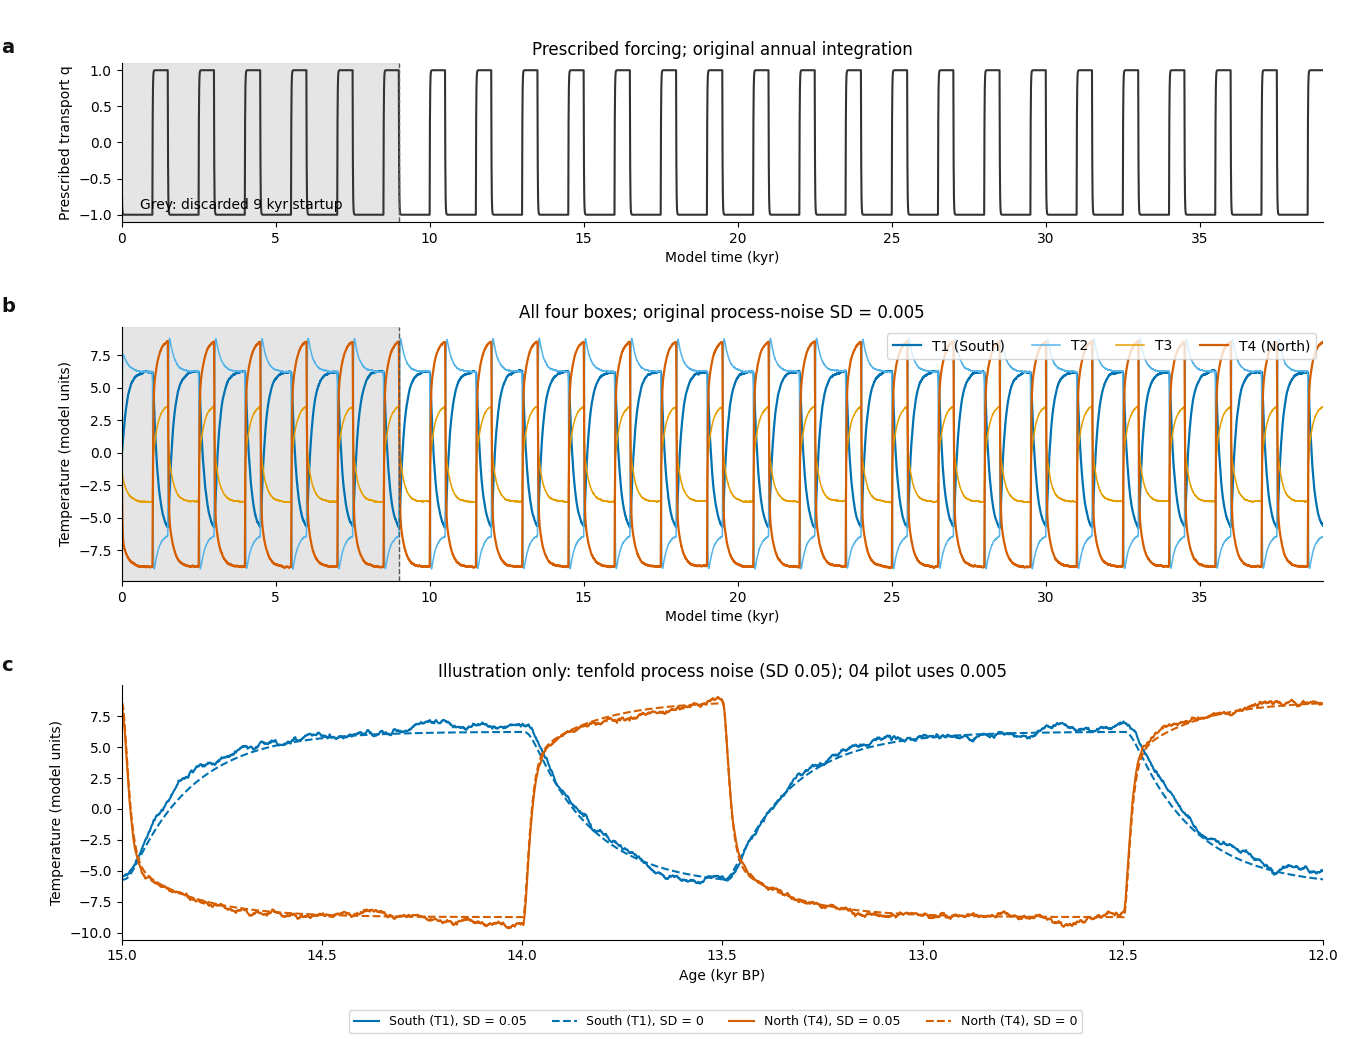

In [2]:
model_time = np.asarray(model['time'], dtype=float)
model_age = (RUNLENGTH - model_time) / 1000.0
temperature = np.asarray(model['temperature'])[0]
noise_free_temperature = np.asarray(deterministic['temperature'])[0]
illustrative_temperature = np.asarray(illustrative_model['temperature'])[0]

fig, axes = plt.subplots(3, 1, figsize=(13.5, 10.5),
                         gridspec_kw={'height_ratios': [1, 1.6, 1.6]})
axes[0].plot(model_time / 1000, model['transport_actual'], color='#333333')
axes[0].set(ylabel='Prescribed transport q', xlabel='Model time (kyr)',
            title='Prescribed forcing; original annual integration')
for box in range(1, 5):
    axes[1].plot(model_time / 1000, temperature[box], color=BOX_COLORS[box - 1],
                 label=f'T{box}' + (' (South)' if box == 1 else ' (North)' if box == 4 else ''),
                 lw=1.1 if box in (2, 3) else 1.6)
axes[1].set(xlabel='Model time (kyr)', ylabel='Temperature (model units)',
            title=f'All four boxes; original process-noise SD = {ORIGINAL_NOISE_SD:g}')
axes[1].legend(ncol=4, loc='upper right')
for ax in axes[:2]:
    ax.axvspan(0, SPINUP_YEARS / 1000, color='0.8', alpha=0.5)
    ax.axvline(SPINUP_YEARS / 1000, color='0.35', ls='--', lw=1)
    ax.set_xlim(0, RUNLENGTH / 1000)
axes[0].text(0.015, 0.08, 'Grey: discarded 9 kyr startup', transform=axes[0].transAxes)
zoom = (model_age <= ZOOM_AGES[0]) & (model_age >= ZOOM_AGES[1])
for box, label in [(1, 'South (T1)'), (4, 'North (T4)')]:
    color = BOX_COLORS[box - 1]
    axes[2].plot(model_age[zoom], illustrative_temperature[box, zoom], color=color,
                 label=f'{label}, SD = {ILLUSTRATIVE_NOISE_SD:g}')
    axes[2].plot(model_age[zoom], noise_free_temperature[box, zoom], color=color,
                 ls='--', lw=1.5, label=f'{label}, SD = 0')
axes[2].set(xlim=ZOOM_AGES, xlabel='Age (kyr BP)', ylabel='Temperature (model units)',
            title=f'Illustration only: tenfold process noise (SD {ILLUSTRATIVE_NOISE_SD:g}); 04 pilot uses {ORIGINAL_NOISE_SD:g}')
handles, labels = axes[2].get_legend_handles_labels()
fig.legend(handles, labels, ncol=4, loc='lower center', bbox_to_anchor=(0.53, 0.01), fontsize=9)
fig.subplots_adjust(left=0.09, right=0.98, top=0.94, bottom=0.105, hspace=0.47)
save_figure(fig, OUTPUT_DIR, '00_model_and_startup', axes=axes)
plt.show()

## 2. Dates change; the sampled temperature values stay fixed

Each uncertain observed chronology is drawn around the accurate sample ages; its ten members are then drawn around that uncertain observed centre. Southern and northern candidate streams are independent. Each whole curve must preserve order and cover the common analysis window. Curves are never sorted, clipped, rescaled or recentered.

The nominal standard deviation $\sigma$ is used separately in both layers. Before acceptance conditioning, a member's single-record error has pointwise SD $\sqrt{2}\sigma$, and the inter-record member error has pointwise SD $2\sigma$. These are not realized RMS values or hard error bounds. Correlation length is fixed at 1000 years, independently of process memory. The top panels show member 1 and its uncertain centre; the lower panels summarize all ten members of this one history.

    process_seed  level  sigma_years record   phase  requested  accepted  attempted  order_rejected  coverage_rejected  acceptance_rate  complete
0       20261009      1         20.0      x  center          1         1          1               0                  0         1.000000      True
1       20261009      1         20.0      x  member         10        10         10               0                  0         1.000000      True
2       20261009      1         20.0      y  center          1         1          1               0                  0         1.000000      True
3       20261009      1         20.0      y  member         10        10         10               0                  0         1.000000      True
4       20261009      2         50.0      x  center          1         1          1               0                  0         1.000000      True
5       20261009      2         50.0      x  member         10        10         10               0                  0      

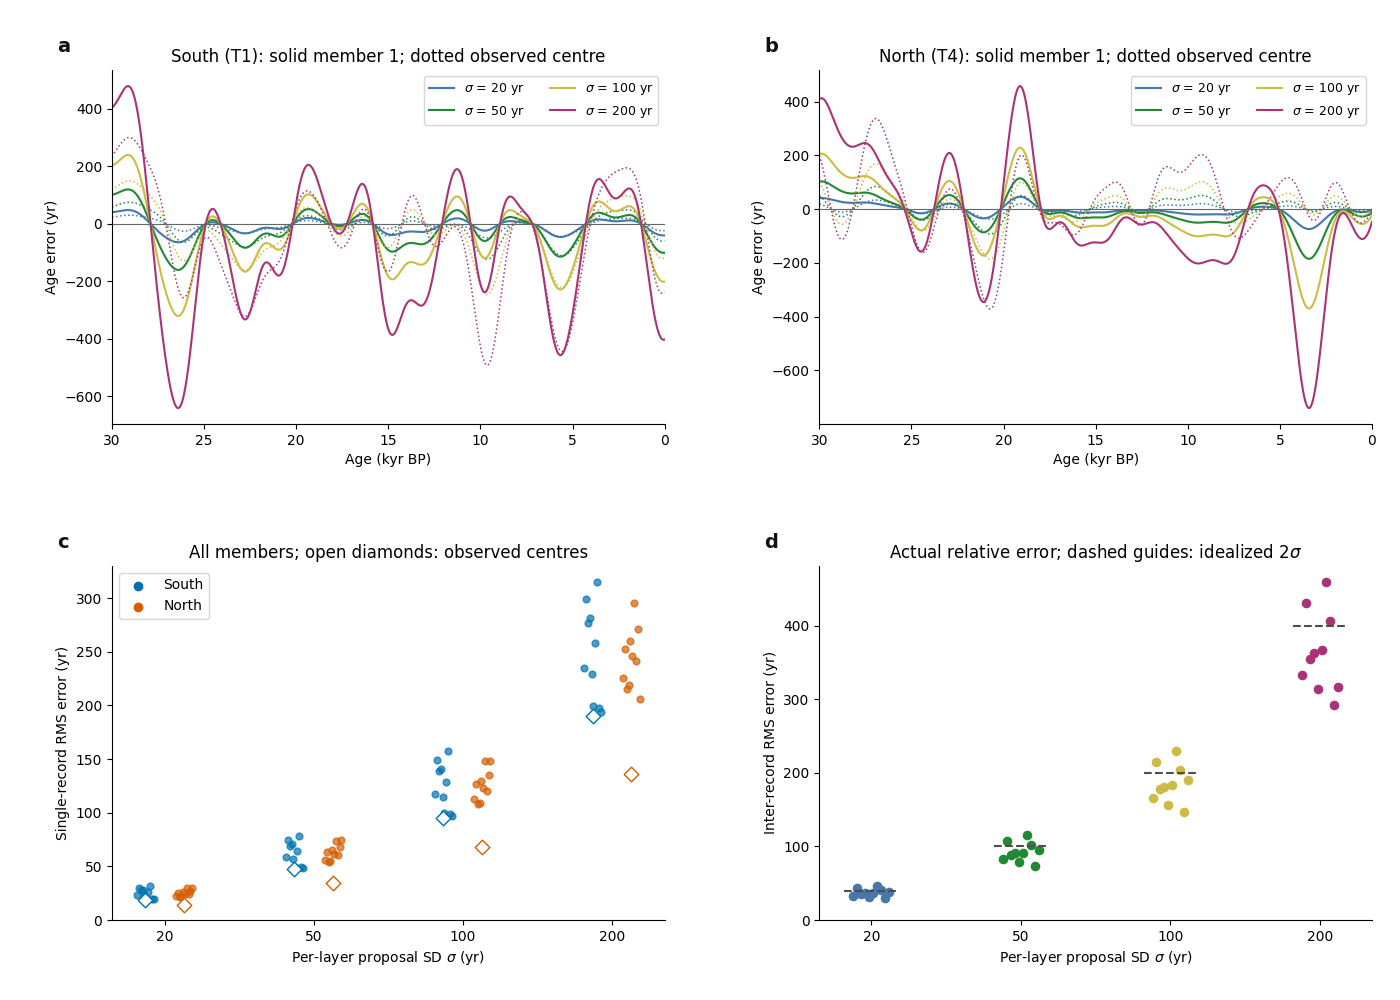

In [3]:
age_true = sampled['age_true'].to_numpy()
analysis_samples = (age_true <= 29.0) & (age_true >= 1.0)
rms_rows = []
relative_rows = []
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
for level, (sigma, color) in enumerate(zip(SIGMA_YEARS, LEVEL_COLORS), start=1):
    for column, (variable, name) in enumerate([('x', 'South (T1)'), ('y', 'North (T4)')]):
        package = chronologies[f'level{level}_{variable}']
        member_error = (np.asarray(package['ages']) - age_true[None, :]) * 1000
        center_error = (np.asarray(package['age_obs']) - age_true) * 1000
        axes[0, column].plot(age_true, member_error[ILLUSTRATIVE_MEMBER], color=color,
                             label=f'$\sigma$ = {sigma} yr')
        axes[0, column].plot(age_true, center_error, color=color, ls=':', lw=1.1)
        member_rms = np.sqrt(np.mean(member_error[:, analysis_samples] ** 2, axis=1))
        center_rms = np.sqrt(np.mean(center_error[analysis_samples] ** 2))
        for member, value in enumerate(member_rms):
            rms_rows.append({'level': level, 'sigma_years': sigma, 'record': name,
                             'member': member, 'member_rms_years': value,
                             'center_rms_years': center_rms})
        position = level + (-0.13 if variable == 'x' else 0.13)
        axes[1, 0].scatter(position + np.linspace(-0.055, 0.055, N_MEMBERS), member_rms,
                           s=24, color=BOX_COLORS[0 if variable == 'x' else 3], alpha=0.7)
        axes[1, 0].scatter(position, center_rms, s=55, marker='D', facecolors='white',
                           edgecolors=BOX_COLORS[0 if variable == 'x' else 3], zorder=4)
    error_x = np.asarray(chronologies[f'level{level}_x']['ages']) - age_true
    error_y = np.asarray(chronologies[f'level{level}_y']['ages']) - age_true
    relative_rms = np.sqrt(np.mean(((error_x - error_y)[:, analysis_samples] * 1000) ** 2, axis=1))
    axes[1, 1].scatter(level + np.linspace(-0.12, 0.12, N_MEMBERS), relative_rms, color=color, s=35)
    axes[1, 1].plot([level - 0.18, level + 0.18], [2 * sigma, 2 * sigma], color='0.3', ls='--')
    for member, value in enumerate(relative_rms):
        relative_rows.append({'level': level, 'member': member, 'relative_rms_years': value})
for column, name in enumerate(['South (T1)', 'North (T4)']):
    axes[0, column].axhline(0, color='0.4', lw=0.8)
    axes[0, column].set(xlim=(30, 0), xlabel='Age (kyr BP)', ylabel='Age error (yr)',
                        title=f'{name}: solid member 1; dotted observed centre')
    axes[0, column].legend(ncol=2, fontsize=9)
for ax in axes[1]:
    ax.set_xticks(range(1, 5), [str(sigma) for sigma in SIGMA_YEARS])
    ax.set_xlabel('Per-layer proposal SD $\sigma$ (yr)')
    ax.set_ylim(bottom=0)
axes[1, 0].set(ylabel='Single-record RMS error (yr)', title='All members; open diamonds: observed centres')
axes[1, 0].scatter([], [], color=BOX_COLORS[0], label='South')
axes[1, 0].scatter([], [], color=BOX_COLORS[3], label='North')
axes[1, 0].legend()
axes[1, 1].set(ylabel='Inter-record RMS error (yr)', title='Actual relative error; dashed guides: idealized $2\sigma$')
fig.subplots_adjust(left=0.08, right=0.98, top=0.93, bottom=0.08, hspace=0.40, wspace=0.28)
save_figure(fig, OUTPUT_DIR, '01_chronology_diagnostics', axes=axes)
plt.show()
rms_table = pd.DataFrame(rms_rows)
relative_table = pd.DataFrame(relative_rows)
display(prepared['diagnostics']['acceptance'])

## 3. Read the same endpoint values on different age axes

Grey curves use accurate ages. Coloured curves use the preselected first accepted member at each level; the observations themselves are unchanged. The two columns keep separate vertical scales, constant down each column. The displayed relative RMS is calculated over 29–1 kyr from the two member age offsets, not from the plotted temperature differences. Shared random proposal streams do not guarantee candidate-by-candidate matching after level-specific rejection.

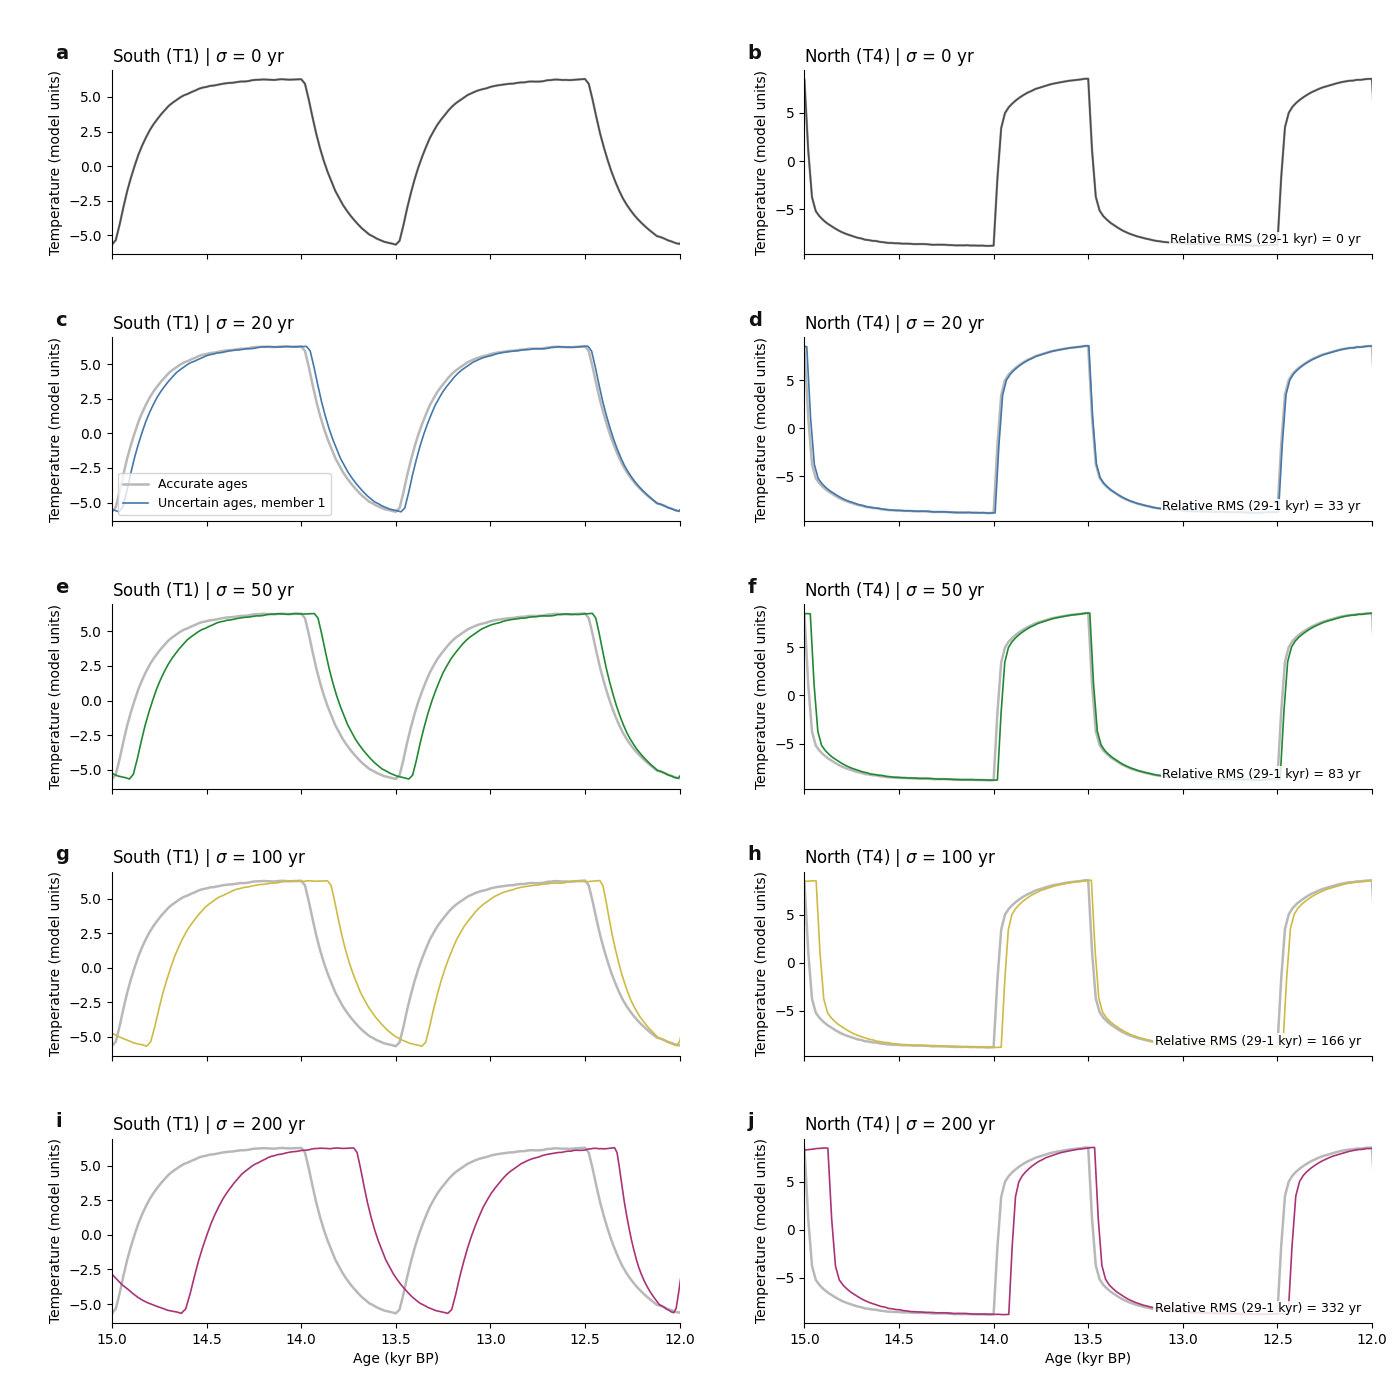

In [4]:
fig, axes = plt.subplots(5, 2, figsize=(14, 14), sharex=True, sharey='col')
for row in range(5):
    sigma = 0 if row == 0 else SIGMA_YEARS[row - 1]
    color = '0.3' if row == 0 else LEVEL_COLORS[row - 1]
    relative_rms = 0.0 if row == 0 else relative_table.loc[
        relative_table.level.eq(row) & relative_table.member.eq(ILLUSTRATIVE_MEMBER),
        'relative_rms_years'].iloc[0]
    for column, (variable, label) in enumerate([('x', 'South (T1)'), ('y', 'North (T4)')]):
        values = sampled[variable].to_numpy()
        member_age = age_true if row == 0 else np.asarray(
            chronologies[f'level{row}_{variable}']['ages'])[ILLUSTRATIVE_MEMBER]
        axes[row, column].plot(age_true, values, color='0.72', lw=1.8, label='Accurate ages')
        axes[row, column].plot(member_age, values, color=color, lw=1.2,
                               label='Accurate' if row == 0 else 'Uncertain ages, member 1')
        axes[row, column].set_xlim(ZOOM_AGES)
        axes[row, column].set_title(f'{label} | $\sigma$ = {sigma} yr', loc='left')
        axes[row, column].set_ylabel('Temperature (model units)')
    axes[row, 1].text(0.98, 0.06, f'Relative RMS (29-1 kyr) = {relative_rms:.0f} yr',
                      transform=axes[row, 1].transAxes, ha='right', fontsize=9,
                      bbox={'facecolor': 'white', 'edgecolor': 'none', 'alpha': 0.85, 'pad': 1})
axes[1, 0].legend(loc='lower left', fontsize=9)
for ax in axes[-1]:
    ax.set_xlabel('Age (kyr BP)')
fig.subplots_adjust(left=0.08, right=0.98, top=0.95, bottom=0.055, hspace=0.45, wspace=0.22)
save_figure(fig, OUTPUT_DIR, '02_records_by_uncertainty', axes=axes)
plt.show()

## 4. Numerical checks before causal comparison

Only the age coordinates and their subsequent interpolation can change the analysis inputs. There is one accurate-age reference per history because synchronous 20-year observations exactly coincide with the analysis grid. All chronology members must cover that same grid; no member-specific cropping or extrapolation is permitted.

In [5]:
accurate_case = next(case for case in prepared['cases'] if case['level'] == 0)
accurate = accurate_case['series']
assert len(sampled) == 1501 and len(age_grid) == 1401
assert np.all(np.diff(age_true) < 0) and np.all(np.diff(age_grid) < 0)
assert np.allclose(accurate['age'], age_grid, rtol=0, atol=1e-12)
assert np.array_equal(accurate[['x', 'y']].to_numpy(), sampled.loc[analysis_samples, ['x', 'y']].to_numpy())

check_rows = []
for key, package in chronologies.items():
    variable = key.rsplit('_', 1)[1]
    ages = np.asarray(package['ages'])
    unchanged = np.array_equal(np.asarray(package['value']), sampled[variable].to_numpy())
    ordered = np.all(np.diff(ages, axis=1) < 0)
    coverage = np.all(ages[:, 0] >= 29.0) and np.all(ages[:, -1] <= 1.0)
    assert unchanged and ordered and coverage
    check_rows.append({'package': key, 'members': len(ages),
                       'values_unchanged': unchanged, 'all_ordered': ordered,
                       'all_cover_29_to_1_kyr': coverage})
display(pd.DataFrame(check_rows))
print('Passed: exact accurate-age input, unchanged values, ordered members, fixed-grid coverage.')
print('Interpretation: one simulated history shown here; production comparisons retain three histories.')

    package  members  values_unchanged  all_ordered  all_cover_29_to_1_kyr
0  level1_x       10              True         True                   True
1  level1_y       10              True         True                   True
2  level2_x       10              True         True                   True
3  level2_y       10              True         True                   True
4  level3_x       10              True         True                   True
5  level3_y       10              True         True                   True
6  level4_x       10              True         True                   True
7  level4_y       10              True         True                   True
Passed: exact accurate-age input, unchanged values, ordered members, fixed-grid coverage.
Interpretation: one simulated history shown here; production comparisons retain three histories.
